# ESE5023 Assignment 03

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# 设置数据文件路径
DATA = Path(".")

## 1. Global methane

### 1.1

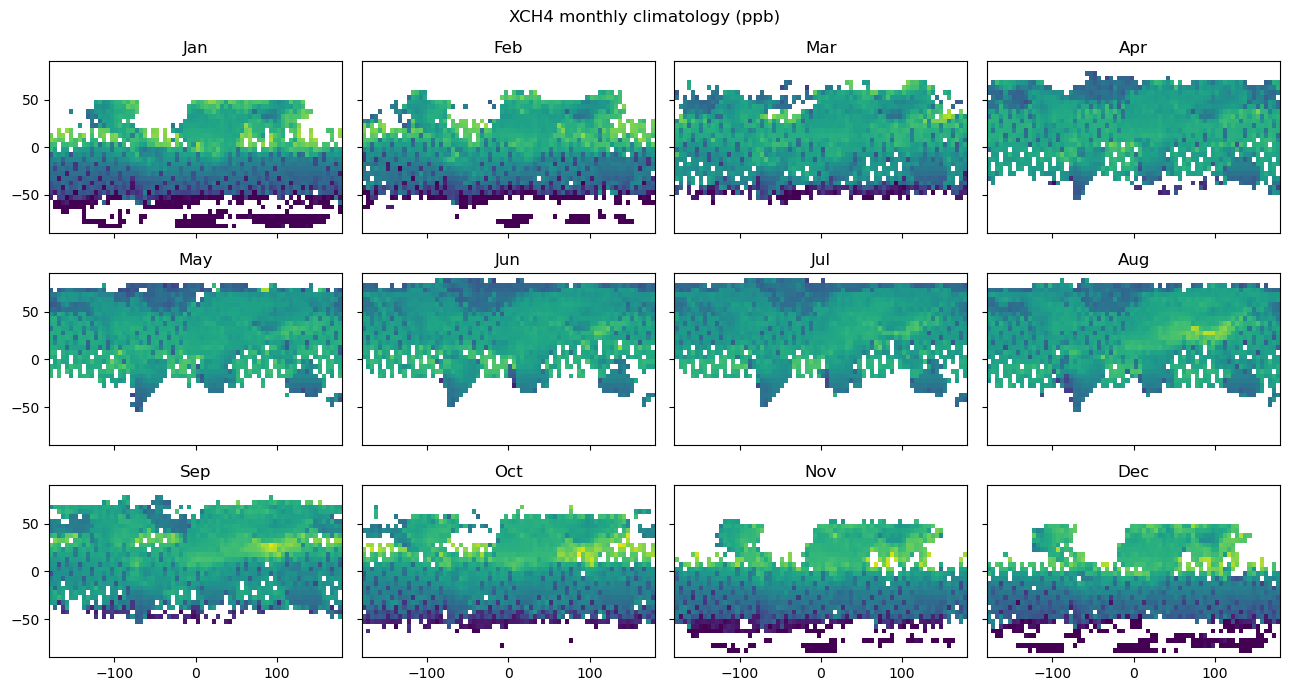

In [2]:
# 读取甲烷数据并计算月气候态
ch4 = xr.open_dataset(DATA / "200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")["xch4"] * 1e9
clim = ch4.groupby("time.month").mean("time")

# 绘制12个月的甲烷气候态
fig, axes = plt.subplots(3, 4, figsize=(13, 7), sharex=True, sharey=True)
for month, ax in enumerate(axes.flat, 1):
    clim.sel(month=month).plot(ax=ax, vmin=1650, vmax=1900, cmap="viridis", add_colorbar=False)
    ax.set_title(pd.Timestamp(2000, month, 1).strftime("%b"))
    ax.set_xlabel(""); ax.set_ylabel("")

fig.suptitle("XCH4 monthly climatology (ppb)")
fig.tight_layout()
plt.show()

### 1.2 

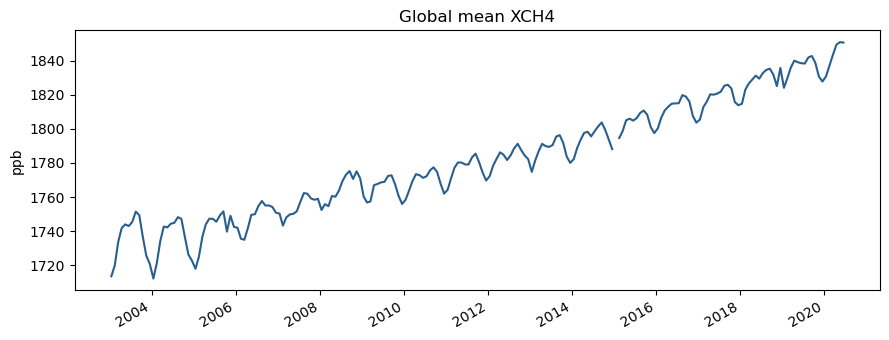

In [3]:
# 计算全球甲烷面积加权平均值
w = np.cos(np.deg2rad(ch4.lat))
ch4_global = ch4.weighted(w).mean(("lat", "lon"))

# 绘制全球平均甲烷时间序列
fig, ax = plt.subplots(figsize=(9, 3.5))
ch4_global.plot(ax=ax, color="#285f8f")
ax.set(title="Global mean XCH4", ylabel="ppb", xlabel="")
fig.tight_layout()
plt.show()

### 1.3 

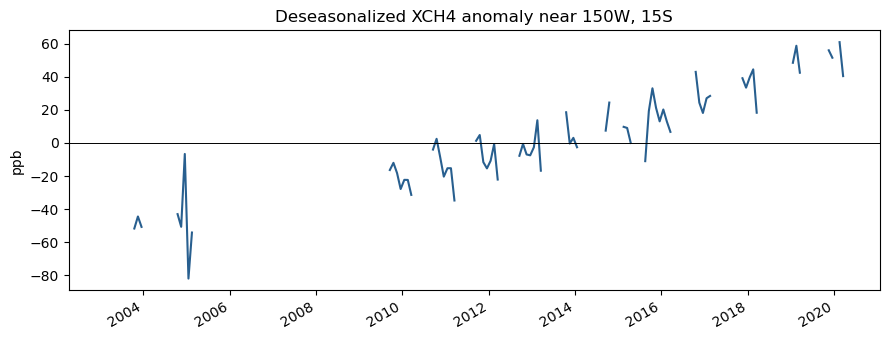

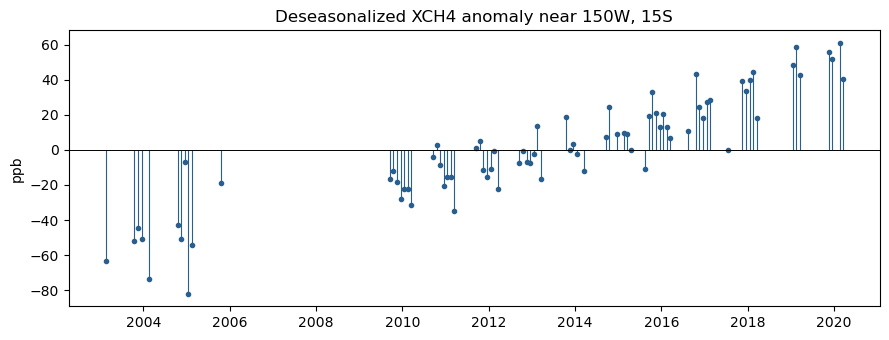

In [4]:
# 计算目标位置的甲烷去季节化异常
point = ch4.sel(lon=-150, lat=-15, method="nearest")
point_anom = point.groupby("time.month") - point.groupby("time.month").mean("time")
valid = point_anom.dropna("time")

# 绘制甲烷异常时间序列（折线图）
fig, ax = plt.subplots(figsize=(9, 3.5))
point_anom.plot(ax=ax, color="#285f8f")
ax.axhline(0, color="black", lw=0.7)
ax.set(title="Deseasonalized XCH4 anomaly near 150W, 15S",
       ylabel="ppb", xlabel="")
fig.tight_layout()
plt.show()
# 绘制甲烷异常时间序列（茎状图）
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.vlines(valid.time, 0, valid, color="#285f8f", lw=0.8)
ax.scatter(valid.time, valid, color="#285f8f", s=9)
ax.axhline(0, color="black", lw=0.7)
ax.set(title="Deseasonalized XCH4 anomaly near 150W, 15S", ylabel="ppb", xlabel="")
fig.tight_layout()
plt.show()

## 2. Niño 3.4 index

### 2.1

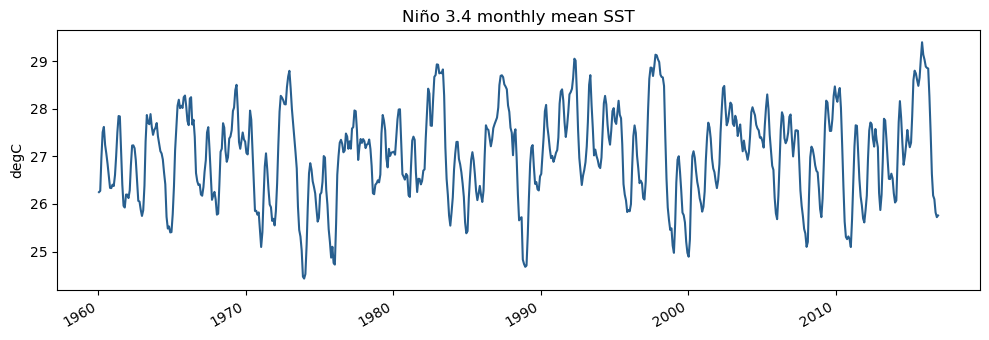

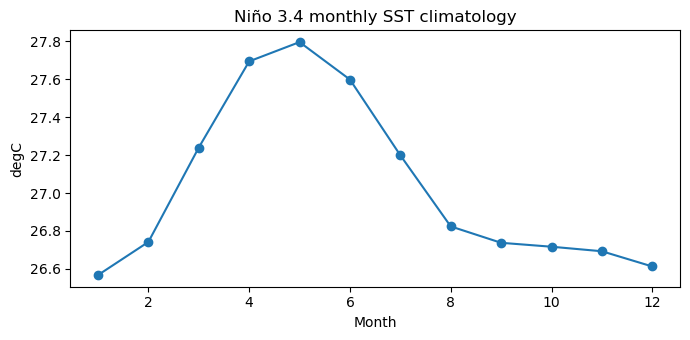

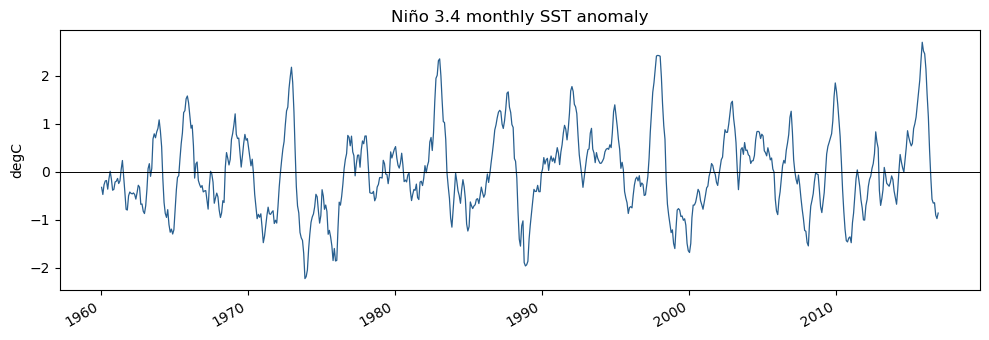

In [4]:
# 计算Niño 3.4区域的海温气候态和异常
sst = xr.open_dataset(DATA / "NOAA_NCDC_ERSST_v3b_SST.nc")["sst"]
nino = sst.sel(lat=slice(-5, 5), lon=slice(190, 240))
nino_mean = nino.weighted(np.cos(np.deg2rad(nino.lat))).mean(("lat", "lon"))
nino_clim = nino_mean.groupby("time.month").mean("time")
nino_anom = nino_mean.groupby("time.month") - nino_clim

# 绘制区域月平均海温时间序列
fig, ax = plt.subplots(figsize=(10, 3.5))
nino_mean.plot(ax=ax, color="#285f8f")
ax.set(title="Niño 3.4 monthly mean SST", ylabel="degC", xlabel="")
fig.tight_layout()
plt.show()

# 绘制海温月气候态
fig, ax = plt.subplots(figsize=(7, 3.5))
nino_clim.plot(ax=ax, marker="o")
ax.set(title="Niño 3.4 monthly SST climatology", ylabel="degC", xlabel="Month")
fig.tight_layout()
plt.show()
# 绘制海温异常时间序列
fig, ax = plt.subplots(figsize=(10, 3.5))
nino_anom.plot(ax=ax, color="#285f8f", lw=0.9)
ax.axhline(0, color="black", lw=0.7)
ax.set(title="Niño 3.4 monthly SST anomaly", ylabel="degC", xlabel="")
fig.tight_layout()
plt.show()


### 2.2

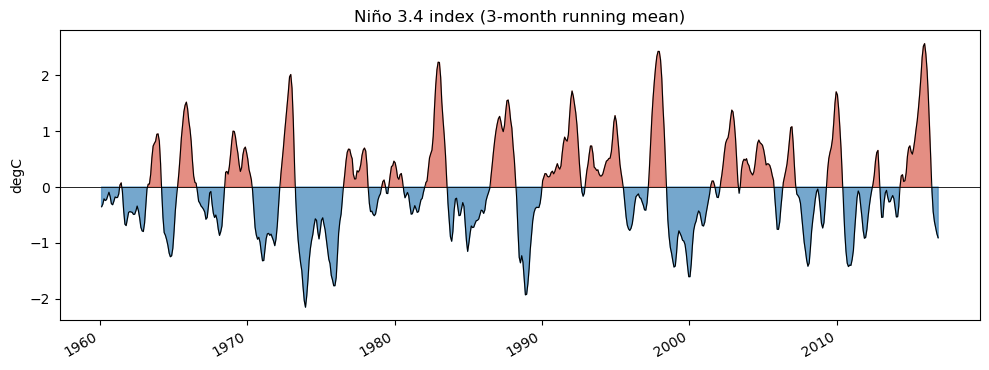

Maximum: 2015-12, 2.56 degC
Minimum: 1973-12, -2.15 degC


In [5]:
# 计算三个月滑动平均并绘制Niño 3.4指数
nino34 = nino_anom.rolling(time=3, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
nino34.plot(ax=ax, color="black", lw=0.8)
ax.fill_between(nino34.time, 0, nino34, where=nino34 >= 0, color="#d95f4f", alpha=0.7)
ax.fill_between(nino34.time, 0, nino34, where=nino34 < 0, color="#3b82b8", alpha=0.7)
ax.axhline(0, color="black", lw=0.6)
ax.set(title="Niño 3.4 index (3-month running mean)", ylabel="degC", xlabel="")
fig.tight_layout()
plt.show()

# 输出指数极值
print(f"Maximum: {nino34.time[nino34.argmax(skipna=True)].dt.strftime('%Y-%m').item()}, {nino34.max().item():.2f} degC")
print(f"Minimum: {nino34.time[nino34.argmin(skipna=True)].dt.strftime('%Y-%m').item()}, {nino34.min().item():.2f} degC")

## 3. Explore a netCDF dataset
### 3.1

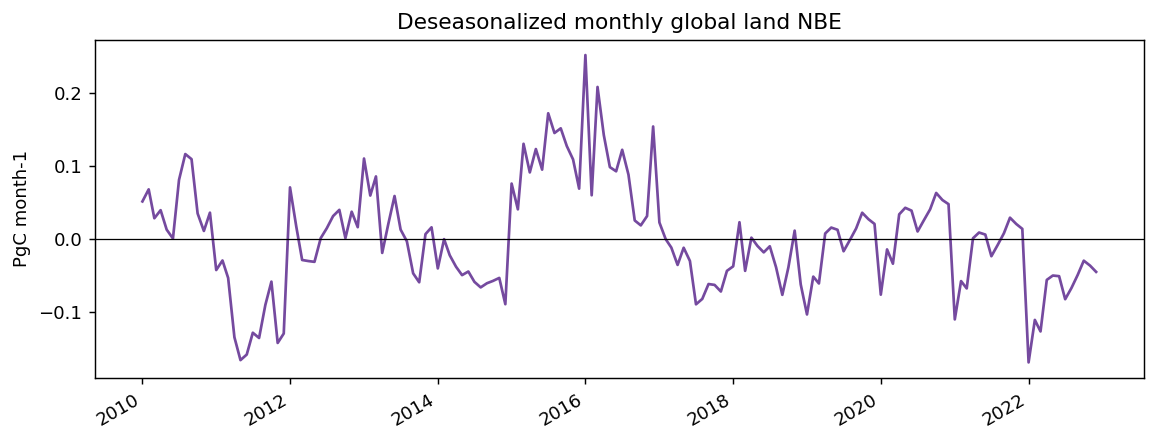

In [7]:
# 读取NASA CMS月度陆地碳通量数据
# 计算全球NBE总量及去季节化异常
cms = xr.open_dataset(DATA / "CMSFluxLandPrior201001_202212_v3.nc", decode_times=False)
cms = cms.assign_coords(time=pd.date_range("2010-01-01", periods=cms.sizes["time"], freq="MS"))
nbe = cms["NBE_prior"]
days = cms.time.dt.days_in_month
global_nbe = (nbe * cms.area).sum(("latitude", "longitude")) * days / 1e15
nbe_anom = global_nbe.groupby("time.month") - global_nbe.groupby("time.month").mean("time")

# 绘制全球NBE异常时间序列
fig, ax = plt.subplots(figsize=(9, 3.5))
nbe_anom.plot(ax=ax, color="#754a9f")
ax.axhline(0, color="black", lw=0.7)
ax.set(title="Deseasonalized monthly global land NBE", ylabel="PgC month-1", xlabel="")
fig.tight_layout()
plt.show()

### 3.2

Mean annual NBE: -2.07 PgC year-1


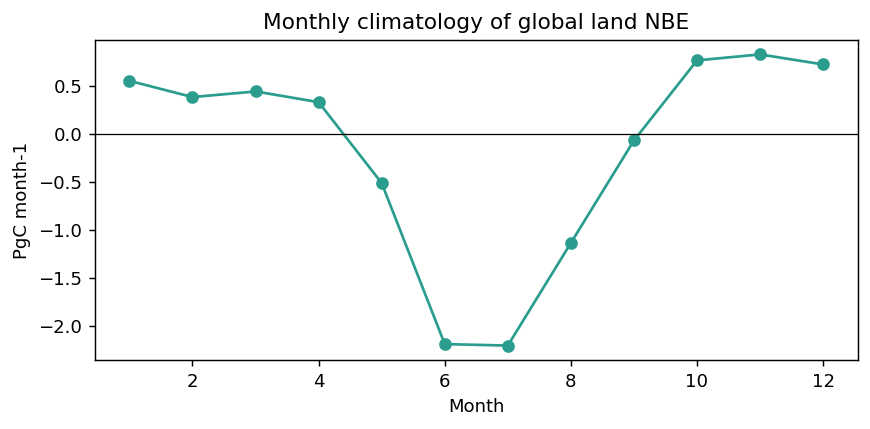

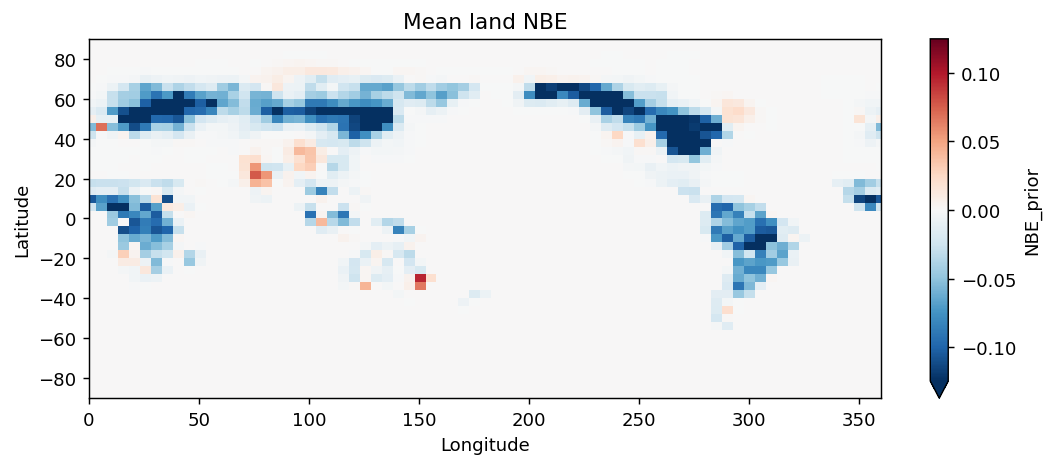

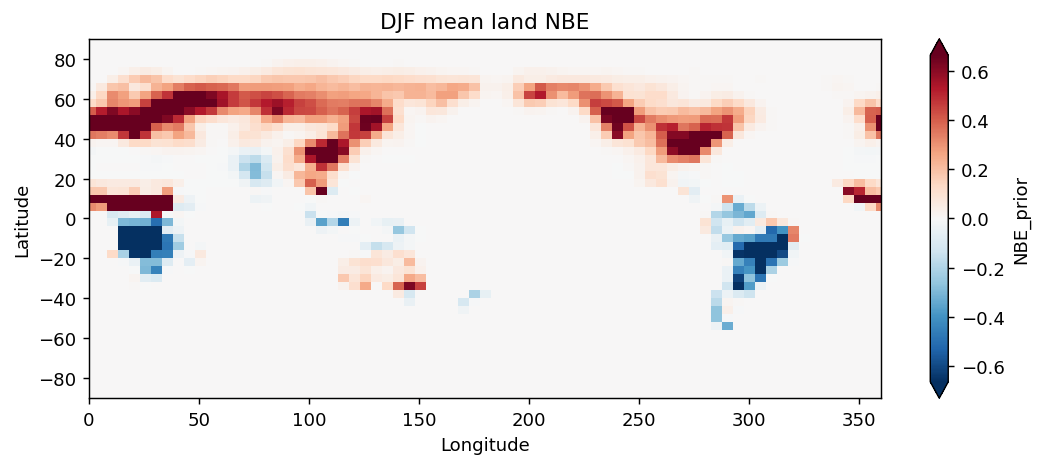

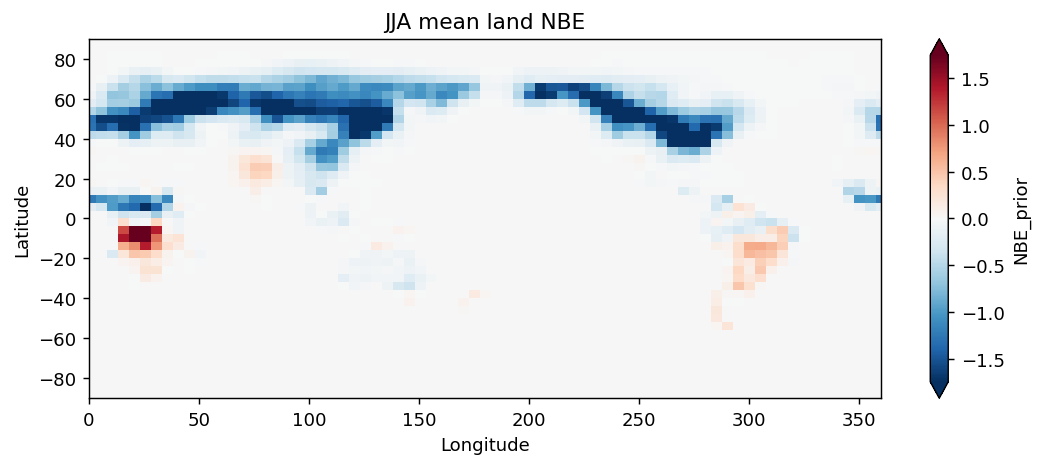

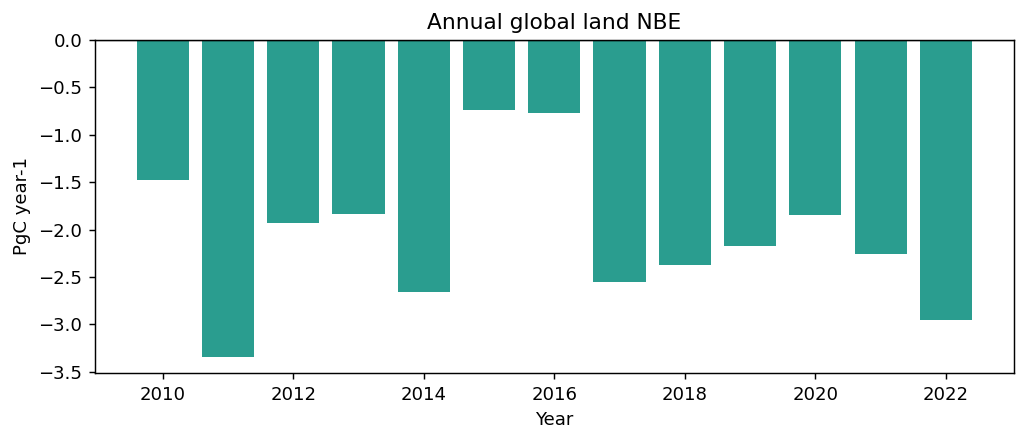

In [8]:
# 绘制NBE月气候态
fig, ax = plt.subplots(figsize=(6.8, 3.4))
global_nbe.groupby("time.month").mean().plot(ax=ax, marker="o", color="#2a9d8f")
ax.axhline(0, color="black", lw=0.7)
ax.set(title="Monthly climatology of global land NBE", ylabel="PgC month-1", xlabel="Month")
fig.tight_layout()
plt.show()

# 绘制NBE多年平均空间分布
fig, ax = plt.subplots(figsize=(8.5, 3.7))
nbe.mean("time").plot(ax=ax, cmap="RdBu_r", robust=True)
ax.set(title="Mean land NBE", xlabel="Longitude", ylabel="Latitude")
fig.tight_layout()
plt.show()

# 绘制冬季NBE空间分布
fig, ax = plt.subplots(figsize=(8.5, 3.7))
nbe.where(nbe.time.dt.season == "DJF", drop=True).mean("time").plot(ax=ax, cmap="RdBu_r", robust=True)
ax.set(title="DJF mean land NBE", xlabel="Longitude", ylabel="Latitude")
fig.tight_layout()
plt.show()

# 绘制夏季NBE空间分布
fig, ax = plt.subplots(figsize=(8.5, 3.7))
nbe.where(nbe.time.dt.season == "JJA", drop=True).mean("time").plot(ax=ax, cmap="RdBu_r", robust=True)
ax.set(title="JJA mean land NBE", xlabel="Longitude", ylabel="Latitude")
fig.tight_layout()
plt.show()

# 绘制全球NBE年总量
annual_nbe = global_nbe.groupby("time.year").sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(annual_nbe.year, annual_nbe, color=np.where(annual_nbe < 0, "#2a9d8f", "#d95f4f"))
ax.axhline(0, color="black", lw=0.7)
ax.set(title="Annual global land NBE", ylabel="PgC year-1", xlabel="Year")
fig.tight_layout()
plt.show()

print(f"Mean annual NBE: {annual_nbe.mean().item():.2f} PgC year-1")